In [6]:
import torch.nn as nn
import torch
import numpy as np


In [7]:
#data generation

sigma, rho, beta = 10.0, 28.0, 8.0 / 3.0
dt = 0.01

def lorenz(x):
    """x: (..., 3) -> dx/dt with the same shape. Works for one state or a batch."""
    x1, x2, x3 = x[..., 0], x[..., 1], x[..., 2]
    return np.stack([sigma * (x2 - x1),
                     x1 * (rho - x3) - x2,
                     x1 * x2 - beta * x3], axis=-1)

def rk4_step(x, dt):
    k1 = lorenz(x)
    k2 = lorenz(x + dt / 2 * k1)
    k3 = lorenz(x + dt / 2 * k2)
    k4 = lorenz(x + dt * k3)
    return x + dt / 6 * (k1 + 2 * k2 + 2 * k3 + k4)

rng = np.random.default_rng(0)
K = 2000
x0 = rng.normal(0, 10, size=(K, 3)) + np.array([0, 0, 25])  # (K, 3); the offset broadcasts over trials

for _ in range(1000):   # burn-in: random starts are off the attractor, so let them settle onto it
    x0 = rk4_step(x0, dt)

data = np.zeros((K, 100, 3), dtype=np.float32)
for k in range(K):
    x = x0[k]
    for t in range(100):
        data[k, t] = x
        x = rk4_step(x, dt)

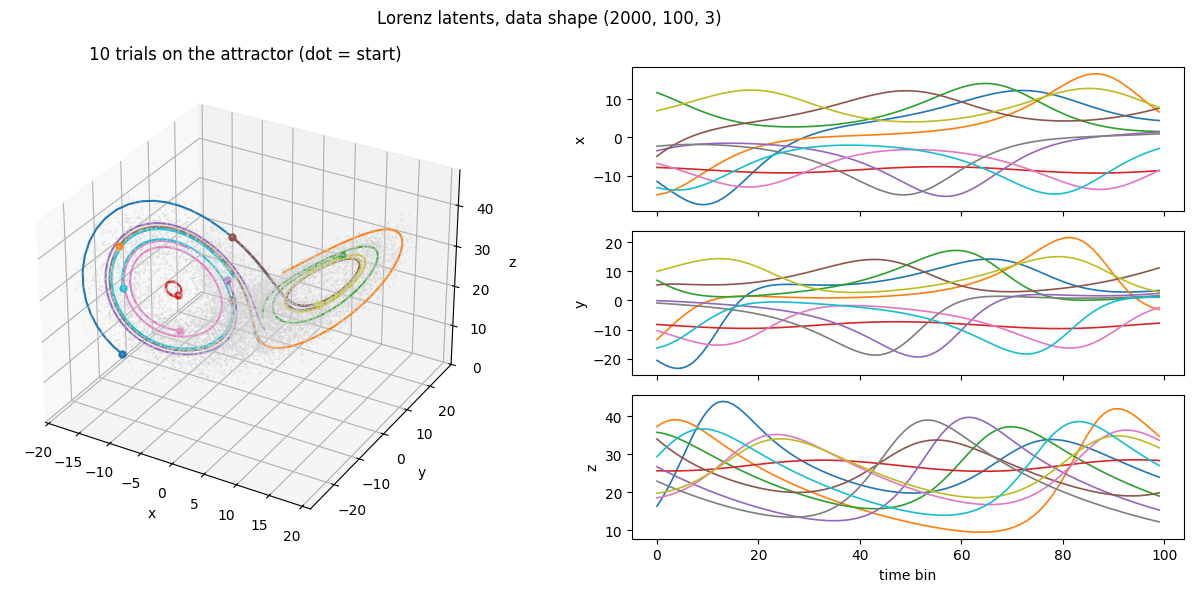

In [10]:
import matplotlib.pyplot as plt

n_show = 10
colors = plt.cm.tab10(np.arange(n_show))
fig = plt.figure(figsize=(13, 6))
gs = fig.add_gridspec(3, 2, width_ratios=[1.2, 1])

# Left: a few single trials in 3-D, over a faint cloud of points from all trials (the attractor)
ax3d = fig.add_subplot(gs[:, 0], projection="3d")
cloud = data.reshape(-1, 3)[::20]
ax3d.scatter(*cloud.T, s=0.3, color="lightgray", alpha=0.4)
for k in range(n_show):
    ax3d.plot(*data[k].T, color=colors[k], lw=1.5)
    ax3d.scatter(*data[k, 0], color=colors[k], s=25)  # dot = trial start
ax3d.set(xlabel="x", ylabel="y", zlabel="z", title=f"{n_show} trials on the attractor (dot = start)")

# Right: the same trials, one latent dimension per row
t_axis = np.arange(data.shape[1])
for i, name in enumerate("xyz"):
    ax = fig.add_subplot(gs[i, 1])
    for k in range(n_show):
        ax.plot(t_axis, data[k, :, i], color=colors[k], lw=1.2)
    ax.set_ylabel(name)
    if i < 2:
        ax.set_xticklabels([])
ax.set_xlabel("time bin")

fig.suptitle(f"Lorenz latents, data shape {data.shape}")
fig.tight_layout()
plt.show()

In [34]:
z = (data - data.mean(axis=(0, 1), keepdims=True)) / data.std(axis=(0, 1), keepdims=True)

N = 30
n_in = 22
rng_neurons = np.random.default_rng(4)
c = rng_neurons.normal(0, 0.5, size=(N, 3)).astype(np.float32)
log_lambda = z @ c.T + np.log(0.05)           # (K, 100, N)
s = rng_neurons.poisson(np.exp(log_lambda), size=(K, 100, N)).astype(np.float32)

train_split = 0.8
train_size = int(K * train_split)
train_data = s[:train_size]
test_data = s[train_size:]


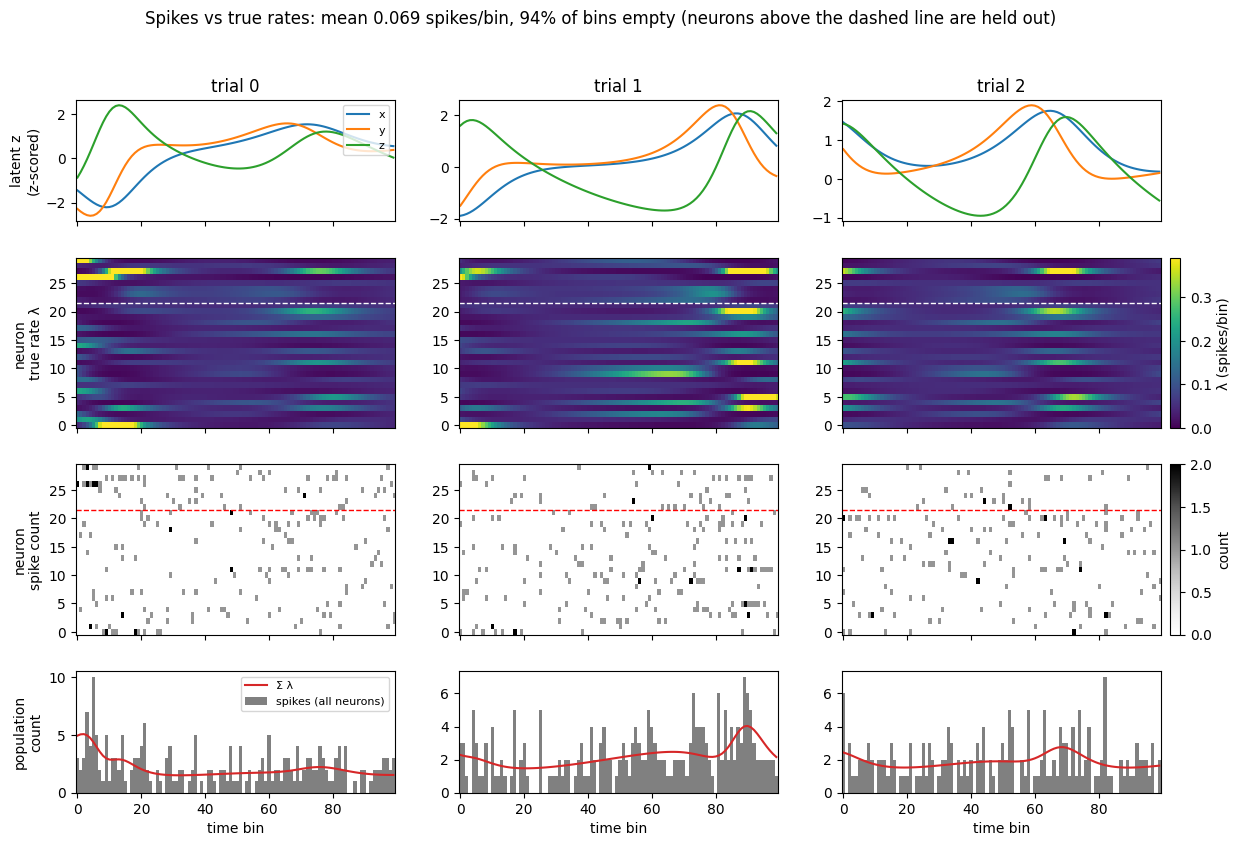

In [35]:
import matplotlib.pyplot as plt

trials = [0, 1, 2]
n_in = 22                      # neurons 22..29 are held out
lam = np.exp(log_lambda)
T = s.shape[1]

fig, axes = plt.subplots(4, len(trials), figsize=(14, 9), sharex=True,
                         gridspec_kw=dict(height_ratios=[1, 1.4, 1.4, 1]))
for j, k in enumerate(trials):
    # 1) latent state driving this trial
    ax = axes[0, j]
    for i, name in enumerate("xyz"):
        ax.plot(z[k, :, i], label=name)
    ax.set_title(f"trial {k}")
    if j == 0: ax.set_ylabel("latent z\n(z-scored)"); ax.legend(loc="upper right", fontsize=8)

    # 2) true firing rates (what LFADS is trying to recover)
    ax = axes[1, j]
    im_rate = ax.imshow(lam[k].T, aspect="auto", origin="lower", cmap="viridis",
                        vmin=0, vmax=np.percentile(lam, 99))
    ax.axhline(n_in - 0.5, color="white", ls="--", lw=1)
    if j == 0: ax.set_ylabel("neuron\ntrue rate λ")

    # 3) observed spike counts (what the model sees)
    ax = axes[2, j]
    im_spk = ax.imshow(s[k].T, aspect="auto", origin="lower", cmap="Greys", vmin=0, vmax=2,
                       interpolation="nearest")
    ax.axhline(n_in - 0.5, color="red", ls="--", lw=1)
    if j == 0: ax.set_ylabel("neuron\nspike count")

    # 4) population: total spikes per bin vs total expected spikes
    ax = axes[3, j]
    ax.bar(np.arange(T), s[k].sum(-1), width=1.0, color="gray", label="spikes (all neurons)")
    ax.plot(lam[k].sum(-1), color="C3", lw=1.5, label="Σ λ")
    ax.set_xlabel("time bin")
    if j == 0: ax.set_ylabel("population\ncount"); ax.legend(loc="upper right", fontsize=8)

# colorbars in insets to the right, so all columns keep the same width
fig.subplots_adjust(right=0.9, hspace=0.25)
fig.colorbar(im_rate, cax=axes[1, -1].inset_axes([1.03, 0, 0.03, 1]), label="λ (spikes/bin)")
fig.colorbar(im_spk, cax=axes[2, -1].inset_axes([1.03, 0, 0.03, 1]), label="count")
fig.suptitle(f"Spikes vs true rates: mean {s.mean():.3f} spikes/bin, {(s == 0).mean():.0%} of bins empty "
             f"(neurons above the dashed line are held out)")
plt.show()

In [36]:
def poisson_ll(rates, spikes):
    """Summed Poisson log-likelihood without log(k!), which cancels in co-bps."""
    rates = np.clip(rates, 1e-9, None)
    return np.sum(spikes * np.log(rates) - rates)

def cobps(pred_rates, spikes_out, train_spikes_out):
    """
    pred_rates:       (K_test, T, N_out) predicted rates, held-out neurons, test trials
    spikes_out:       (K_test, T, N_out) observed spikes, same neurons and trials
    train_spikes_out: (K_train, T, N_out) only used for the null model's mean rate per neuron
    """
    null_rates = train_spikes_out.mean(axis=(0, 1), keepdims=True)      # (1, 1, N_out)
    ll_model = poisson_ll(pred_rates, spikes_out)
    ll_null = poisson_ll(np.broadcast_to(null_rates, spikes_out.shape), spikes_out)
    return (ll_model - ll_null) / (spikes_out.sum() * np.log(2))


In [37]:
from scipy.ndimage import gaussian_filter1d

def fit_glm_baseline(sd):
    # inputs: smoothed held-in neurons. targets: RAW held-out counts (never smoothed)
    X_tr = torch.from_numpy(gaussian_filter1d(train_data[:, :, :n_in], sigma=sd, axis=1)).reshape(-1, n_in)
    X_te = torch.from_numpy(gaussian_filter1d(test_data[:, :, :n_in], sigma=sd, axis=1)).reshape(-1, n_in)
    Y_tr = torch.from_numpy(train_data[:, :, n_in:]).reshape(-1, N - n_in)

    glm = nn.Linear(n_in, N - n_in)
    loss_fn = nn.PoissonNLLLoss(log_input=True)     # glm output is already log λ
    opt = torch.optim.LBFGS(glm.parameters(), max_iter=20, line_search_fn="strong_wolfe")

    def closure():
        opt.zero_grad()
        loss = loss_fn(glm(X_tr), Y_tr)
        loss.backward()
        return loss

    for _ in range(50):
        loss = opt.step(closure)

    with torch.no_grad():
        rates_te = torch.exp(glm(X_te)).reshape(test_data.shape[0], -1, N - n_in).numpy()
    return cobps(rates_te, test_data[:, :, n_in:], train_data[:, :, n_in:]), loss.item()

for sd in [1, 2, 3, 5, 8, 12, 16]:
    score, train_loss = fit_glm_baseline(sd)
    print(f"sd={sd}: train NLL={train_loss:.4f}  test co-bps={score:.3f}")


sd=1: train NLL=0.2593  test co-bps=0.304
sd=2: train NLL=0.2537  test co-bps=0.401
sd=3: train NLL=0.2510  test co-bps=0.452
sd=5: train NLL=0.2485  test co-bps=0.498
sd=8: train NLL=0.2480  test co-bps=0.505
sd=12: train NLL=0.2497  test co-bps=0.471
sd=16: train NLL=0.2521  test co-bps=0.425


In [28]:
from scipy.ndimage import convolve1d

def smooth(spikes, sd, leave_one_out=False):
    """Gaussian smoothing along time. leave_one_out=True removes each bin's own spike from its estimate."""
    r = int(4 * sd + 0.5)
    w = np.exp(-0.5 * (np.arange(-r, r + 1) / sd) ** 2)
    if leave_one_out:
        w[r] = 0.0
    w /= w.sum()
    # mode="constant": no reflection at trial edges, so a bin's own spike can't sneak back in
    num = convolve1d(spikes, w, axis=1, mode="constant")
    den = convolve1d(np.ones_like(spikes), w, axis=1, mode="constant")   # renormalise near the edges
    return num / den

s_te_out, s_tr_out = test_data[:, :, n_in:], train_data[:, :, n_in:]
null = s_tr_out.mean(axis=(0, 1), keepdims=True)
print(f"true rates: {cobps(np.exp(log_lambda[train_size:, :, n_in:]), s_te_out, s_tr_out):.3f}")
for sd in [0.5, 1, 2, 3, 5, 8, 16]:
    leaky = cobps(smooth(s_te_out, sd), s_te_out, s_tr_out)
    loo = cobps(0.9 * smooth(s_te_out, sd, leave_one_out=True) + 0.1 * null, s_te_out, s_tr_out)
    print(f"sd={sd}: same-neuron={leaky:.3f}  leave-one-out={loo:.3f}")


true rates: 0.255
sd=0.5: same-neuron=3.807  leave-one-out=-2.319
sd=1: same-neuron=2.944  leave-one-out=-1.793
sd=2: same-neuron=2.147  leave-one-out=-1.161
sd=3: same-neuron=1.740  leave-one-out=-0.819
sd=5: same-neuron=1.300  leave-one-out=-0.469
sd=8: same-neuron=0.973  leave-one-out=-0.242
sd=16: same-neuron=0.616  leave-one-out=-0.071


This beats the true rates as 

In [38]:
class GRUEncoder(nn.Module):
    """Reads a whole trial of held-in spikes and outputs q(g0 | x) = N(mu, diag(exp(logvar)))."""
    def __init__(self, n_in, hidden=64, g_dim=64, dropout=0.05):
        super().__init__()
        self.dropout = nn.Dropout(dropout)
        self.gru = nn.GRU(n_in, hidden, batch_first=True, bidirectional=True)
        self.to_posterior = nn.Linear(2 * hidden, 2 * g_dim)

    def forward(self, x):                           # x: (B, T, n_in)
        _, h_n = self.gru(self.dropout(x))          # h_n: (2, B, hidden), last state of each direction
        h = torch.cat([h_n[0], h_n[1]], dim=-1)     # (B, 2*hidden): summary of the whole trial
        mu, logvar = self.to_posterior(self.dropout(h)).chunk(2, dim=-1)
        return mu, logvar                           # each (B, g_dim)


class GRUGenerator(nn.Module):
    """Autonomous RNN: starts at g0, runs T steps with no input, reads out low-d factors."""
    def __init__(self, g_dim=64, f_dim=8, dropout=0.05):
        super().__init__()
        self.gru = nn.GRU(1, g_dim, batch_first=True)   # input size 1, always fed zeros
        self.dropout = nn.Dropout(dropout)
        self.to_factors = nn.Linear(g_dim, f_dim, bias=False)

    def forward(self, g0, T):                       # g0: (B, g_dim)
        zeros = g0.new_zeros(g0.shape[0], T, 1)
        g, _ = self.gru(zeros, g0.unsqueeze(0))     # initial hidden must be (1, B, g_dim); g: (B, T, g_dim)
        return self.to_factors(self.dropout(g))     # (B, T, f_dim)


class LFADS(nn.Module):
    def __init__(self, n_in, n_out, enc_hidden=64, g_dim=64, f_dim=8, dropout=0.05):
        super().__init__()
        self.encoder = GRUEncoder(n_in, enc_hidden, g_dim, dropout)
        self.generator = GRUGenerator(g_dim, f_dim, dropout)
        self.readout = nn.Linear(f_dim, n_out)      # Poisson GLM on the factors -> log-rates

    def forward(self, x, sample=True):
        mu, logvar = self.encoder(x)
        if sample:   # reparameterisation: g0 = mu + sigma * eps, so gradients reach mu and logvar
            g0 = mu + torch.exp(0.5 * logvar) * torch.randn_like(mu)
        else:        # at evaluation use the posterior mean
            g0 = mu
        factors = self.generator(g0, x.shape[1])
        log_rates = self.readout(factors)           # (B, T, n_out)
        return log_rates, factors, mu, logvar


def lfads_loss(log_rates, spikes, mu, logvar, kl_weight):
    """Negative ELBO per trial: Poisson NLL summed over time and neurons, plus weighted KL to N(0, I)."""
    nll = nn.functional.poisson_nll_loss(log_rates, spikes, log_input=True, full=False,
                                         reduction="sum") / spikes.shape[0]
    kl = 0.5 * (mu.pow(2) + logvar.exp() - 1 - logvar).sum(-1).mean()
    return nll + kl_weight * kl, nll, kl

In [39]:
# Smoke test: check shapes before training
model = LFADS(n_in=n_in, n_out=N)
x = torch.from_numpy(train_data[:4])                      # (4, 100, 30)
log_rates, factors, mu, logvar = model(x[:, :, :n_in])    # encoder only sees held-in neurons
loss, nll, kl = lfads_loss(log_rates, x, mu, logvar, kl_weight=1.0)   # loss uses all 30 neurons
print(log_rates.shape, factors.shape, mu.shape, loss.item())
print("params:", sum(p.numel() for p in model.parameters()))

torch.Size([4, 100, 30]) torch.Size([4, 100, 8]) torch.Size([4, 64]) 3282.86572265625
params: 63950


In [40]:
import time
device = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(0)

X_tr = torch.from_numpy(train_data).to(device)        # (1600, 100, 30)
X_te = torch.from_numpy(test_data).to(device)         # (400, 100, 30)
s_te_out, s_tr_out = test_data[:, :, n_in:], train_data[:, :, n_in:]
oracle = cobps(np.exp(log_lambda[train_size:, :, n_in:]), s_te_out, s_tr_out)

model = LFADS(n_in=n_in, n_out=N).to(device)
opt = torch.optim.Adam(model.parameters(), lr=3e-3)
n_epochs, batch_size, kl_warmup = 200, 100, 50

def evaluate(model):
    """Infer from held-in neurons of test trials (posterior mean), score held-out neurons."""
    model.eval()
    with torch.no_grad():
        log_rates, factors, _, _ = model(X_te[:, :, :n_in], sample=False)
    rates = log_rates.exp().cpu().numpy()             # (400, 100, 30)
    return cobps(rates[:, :, n_in:], s_te_out, s_tr_out), rates, factors.cpu().numpy()

history = {"epoch": [], "nll": [], "kl": [], "eval_epoch": [], "cobps": []}
t0 = time.time()
for epoch in range(n_epochs):
    model.train()
    kl_weight = min(1.0, epoch / kl_warmup)           # KL warm-up: let reconstruction learn first
    perm = torch.randperm(len(X_tr), device=device)
    ep_nll = ep_kl = 0.0
    for i in range(0, len(X_tr), batch_size):
        xb = X_tr[perm[i:i + batch_size]]
        log_rates, _, mu, logvar = model(xb[:, :, :n_in])        # encoder sees held-in only
        loss, nll, kl = lfads_loss(log_rates, xb, mu, logvar, kl_weight)   # loss on all 30
        opt.zero_grad()
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 200.0)
        opt.step()
        ep_nll += nll.item() * len(xb)
        ep_kl += kl.item() * len(xb)
    history["epoch"].append(epoch)
    history["nll"].append(ep_nll / len(X_tr))
    history["kl"].append(ep_kl / len(X_tr))
    if epoch % 5 == 0 or epoch == n_epochs - 1:
        score, _, _ = evaluate(model)
        history["eval_epoch"].append(epoch)
        history["cobps"].append(score)
        print(f"epoch {epoch:3d}  {time.time() - t0:4.0f}s  NLL/trial {history['nll'][-1]:7.1f}  "
              f"KL {history['kl'][-1]:5.1f}  kl_w {kl_weight:.2f}  test co-bps {score:.3f}")

score, rates_te, factors_te = evaluate(model)
print(f"\nfinal test co-bps {score:.3f}   (true rates {oracle:.3f})")

epoch   0     5s  NLL/trial  2729.3  KL  33.7  kl_w 0.00  test co-bps -7.764
epoch   5    25s  NLL/trial   750.3  KL   9.5  kl_w 0.10  test co-bps -0.001
epoch  10    45s  NLL/trial   746.1  KL  10.9  kl_w 0.20  test co-bps 0.088
epoch  15    65s  NLL/trial   736.5  KL   8.7  kl_w 0.30  test co-bps 0.181
epoch  20    87s  NLL/trial   730.4  KL   9.4  kl_w 0.40  test co-bps 0.247
epoch  25   111s  NLL/trial   728.6  KL   8.5  kl_w 0.50  test co-bps 0.269
epoch  30   132s  NLL/trial   725.3  KL   8.8  kl_w 0.60  test co-bps 0.325
epoch  35   153s  NLL/trial   720.4  KL   8.7  kl_w 0.70  test co-bps 0.379
epoch  40   172s  NLL/trial   714.1  KL   9.2  kl_w 0.80  test co-bps 0.429
epoch  45   193s  NLL/trial   705.8  KL  10.1  kl_w 0.90  test co-bps 0.471
epoch  50   213s  NLL/trial   702.1  KL   9.6  kl_w 1.00  test co-bps 0.535
epoch  55   234s  NLL/trial   701.0  KL   9.6  kl_w 1.00  test co-bps 0.528
epoch  60   255s  NLL/trial   698.8  KL   9.5  kl_w 1.00  test co-bps 0.551
epoch  65 

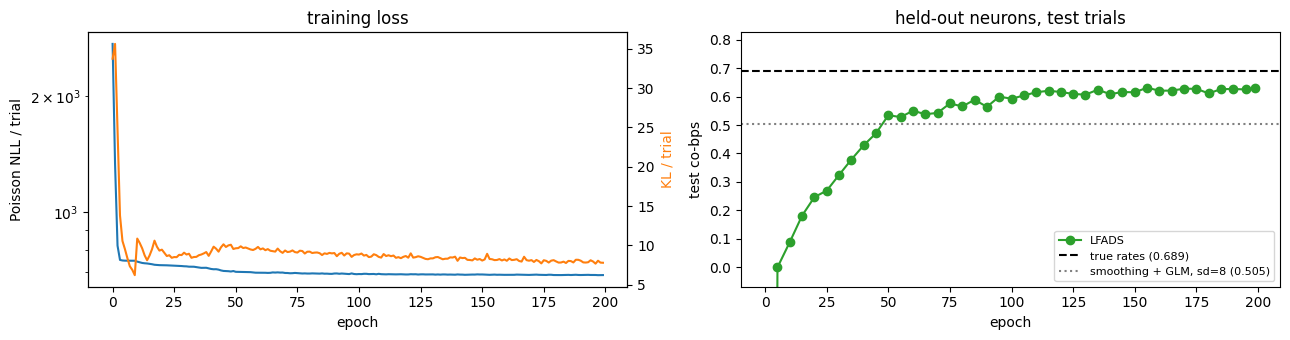

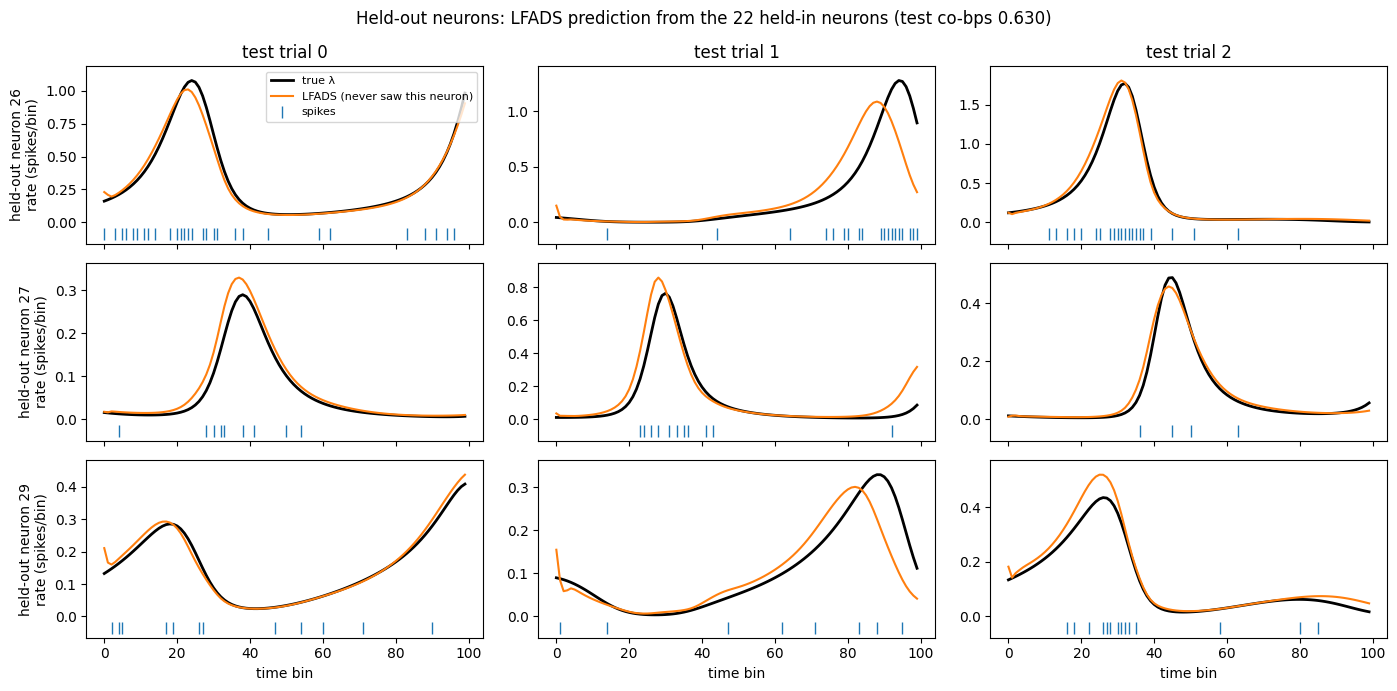

In [41]:
best_sd = 8                                           # best kernel width from your baseline sweep
baseline_score, _ = fit_glm_baseline(best_sd)
lam_te = np.exp(log_lambda[train_size:])              # true rates on test trials

# ---- Figure 1: training ----
fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
ax = axes[0]
ax.plot(history["epoch"], history["nll"], color="C0")
ax.set(xlabel="epoch", ylabel="Poisson NLL / trial", title="training loss", yscale="log")
ax_kl = ax.twinx()
ax_kl.plot(history["epoch"], history["kl"], color="C1")
ax_kl.set_ylabel("KL / trial", color="C1")

ax = axes[1]
ax.plot(history["eval_epoch"], history["cobps"], "o-", color="C2", label="LFADS")
ax.axhline(oracle, color="k", ls="--", label=f"true rates ({oracle:.3f})")
ax.axhline(baseline_score, color="gray", ls=":", label=f"smoothing + GLM, sd={best_sd} ({baseline_score:.3f})")
ax.set_ylim(-0.1 * oracle, 1.2 * oracle)              # early epochs are very negative; clip them
ax.set(xlabel="epoch", ylabel="test co-bps", title="held-out neurons, test trials")
ax.legend(loc="lower right", fontsize=8)
fig.tight_layout()
plt.show()

# ---- Figure 2: predicted vs true rates for held-out neurons on test trials ----
held_out = np.arange(n_in, N)
# the held-out neurons whose true rate varies most carry the most signal
show_neurons = held_out[np.argsort(lam_te[:, :, held_out].std(axis=(0, 1)))[::-1][:3]]
show_trials = [0, 1, 2]

fig, axes = plt.subplots(len(show_neurons), len(show_trials), figsize=(14, 7), sharex=True)
for r, n in enumerate(show_neurons):
    for col, k in enumerate(show_trials):
        ax = axes[r, col]
        top = max(lam_te[k, :, n].max(), rates_te[k, :, n].max())
        ax.plot(lam_te[k, :, n], color="k", lw=2, label="true λ")
        ax.plot(rates_te[k, :, n], color="C1", lw=1.5, label="LFADS (never saw this neuron)")
        spike_t = np.nonzero(test_data[k, :, n])[0]
        ax.plot(spike_t, np.full(len(spike_t), -0.08 * top), "|", color="C0", ms=8, label="spikes")
        ax.set_ylim(-0.15 * top, 1.1 * top)
        if r == 0:
            ax.set_title(f"test trial {k}")
        if col == 0:
            ax.set_ylabel(f"held-out neuron {n}\nrate (spikes/bin)")
        if r == len(show_neurons) - 1:
            ax.set_xlabel("time bin")
axes[0, 0].legend(loc="upper right", fontsize=8)
fig.suptitle(f"Held-out neurons: LFADS prediction from the {n_in} held-in neurons (test co-bps {score:.3f})")
fig.tight_layout()
plt.show()

In [42]:
def latent_r2(feat_tr, feat_te, z_tr, z_te):
    """Least-squares map features -> z (with bias), fit on train trials; R² per latent dim on test trials."""
    A_tr = np.c_[feat_tr.reshape(-1, feat_tr.shape[-1]), np.ones(feat_tr.shape[0] * feat_tr.shape[1])]
    A_te = np.c_[feat_te.reshape(-1, feat_te.shape[-1]), np.ones(feat_te.shape[0] * feat_te.shape[1])]
    W, *_ = np.linalg.lstsq(A_tr, z_tr.reshape(-1, 3), rcond=None)       # (F + 1, 3)
    z_hat = (A_te @ W).reshape(z_te.shape)
    ss_res = ((z_hat - z_te) ** 2).sum(axis=(0, 1))
    ss_tot = ((z_te - z_te.mean(axis=(0, 1))) ** 2).sum(axis=(0, 1))
    return 1 - ss_res / ss_tot, z_hat

# LFADS factors for the training trials (posterior mean, held-in neurons only, same as at test time)
model.eval()
with torch.no_grad():
    _, factors_tr, _, _ = model(X_tr[:, :, :n_in], sample=False)
factors_tr = factors_tr.cpu().numpy()                                     # (1600, 100, 8)

z_tr, z_te = z[:train_size], z[train_size:]
r2_lfads, z_hat_lfads = latent_r2(factors_tr, factors_te, z_tr, z_te)

# the same linear map from smoothed held-in spikes, for comparison
sm_tr = gaussian_filter1d(train_data[:, :, :n_in], sigma=best_sd, axis=1)
sm_te = gaussian_filter1d(test_data[:, :, :n_in], sigma=best_sd, axis=1)
r2_smooth, z_hat_smooth = latent_r2(sm_tr, sm_te, z_tr, z_te)

print("test R² per latent dim         x      y      z")
print(f"smoothed spikes (sd={best_sd})     " + "  ".join(f"{v:.3f}" for v in r2_smooth))
print(f"LFADS factors                " + "  ".join(f"{v:.3f}" for v in r2_lfads))

test R² per latent dim         x      y      z
smoothed spikes (sd=8)     0.814  0.742  0.818
LFADS factors                0.953  0.938  0.916


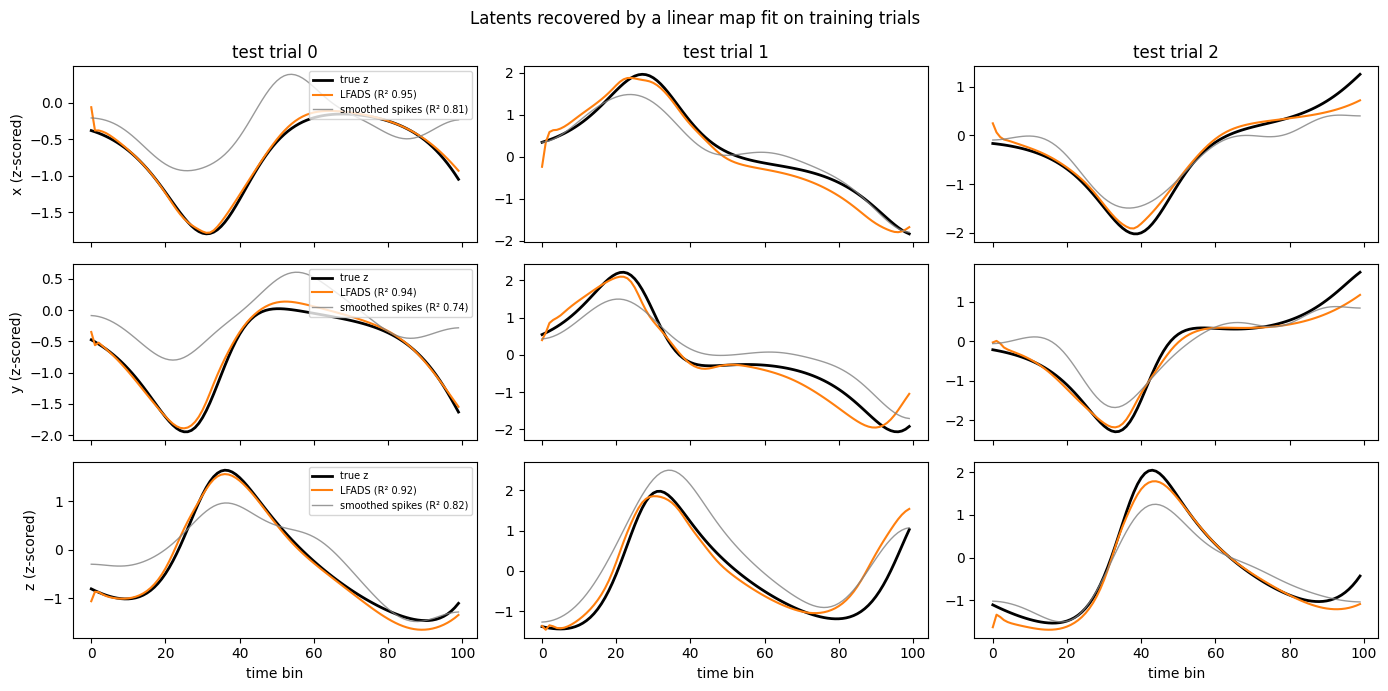

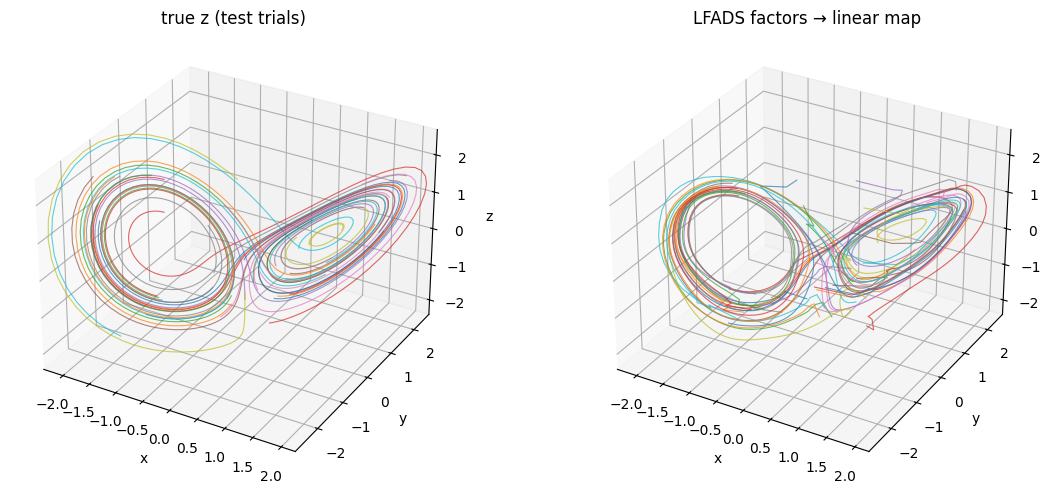

In [ ]:
# ---- single test trials: true z vs linear read-out of LFADS factors / smoothed spikes ----
show_trials = [0, 1, 2]
fig, axes = plt.subplots(3, len(show_trials), figsize=(14, 7), sharex=True)
for d, name in enumerate("xyz"):
    for col, k in enumerate(show_trials):
        ax = axes[d, col]
        ax.plot(z_te[k, :, d], color="k", lw=2, label="true z")
        ax.plot(z_hat_lfads[k, :, d], color="C1", lw=1.5, label=f"LFADS (R² {r2_lfads[d]:.2f})")
        ax.plot(z_hat_smooth[k, :, d], color="gray", lw=1, alpha=0.8, label=f"smoothed spikes (R² {r2_smooth[d]:.2f})")
        if d == 0:
            ax.set_title(f"test trial {k}")
        if col == 0:
            ax.set_ylabel(f"{name} (z-scored)")
            ax.legend(loc="upper right", fontsize=7)
        if d == 2:
            ax.set_xlabel("time bin")
        
fig.suptitle("Latents recovered by a linear map fit on training trials")
fig.tight_layout()
plt.show()

# ---- 3-D attractor: true vs LFADS read-out, many test trials ----
n_traj = 30
lims = [(z_te[:n_traj, :, d].min(), z_te[:n_traj, :, d].max()) for d in range(3)]   # same axes for both
fig = plt.figure(figsize=(12, 5))
for p, (traj, title) in enumerate([(z_te, "true z (test trials)"),
                                   (z_hat_lfads, "LFADS factors → linear map")]):
    ax = fig.add_subplot(1, 2, p + 1, projection="3d")
    for k in range(n_traj):
        ax.plot(*traj[k].T, lw=0.8, alpha=0.7)
    ax.set(xlabel="x", ylabel="y", zlabel="z", title=title, xlim=lims[0], ylim=lims[1], zlim=lims[2])
fig.tight_layout()
plt.show()


$z$ can only be recovered up to an affine scale as the latent states are being deduced from solely the spikes, any transform can be absorbed into the readout weights. The generative model is described as follows

$$
\dot z = F(z), \quad \log{\lambda_t} = b + Cz_t, \quad s_{n,t} \sim \mathrm{Poisson}(\lambda_{n,t})    
$$
Where $C\in \mathbb R^{30\times3}$. Everything we can learn from this is the distribution of spikes and that depends on $z$ solely through the rates. The data will only constrain these rates, it does not necessarily constrain the generative parameters. If two different latent descriptors produce identical rates on every trial and bin, no amount of data can tell them apart. The rate equations survive affine transformations as they are accounted for in the learned parameters $C'$ and $b'$. 

$$
z'_t = Az_t +d,\quad C' = CA^{-1},\quad b' = b - CA^{-1}d.
$$

Then, 

$$
b' + C'z'_t = b - CA^{-1}d + CA^{-1}(Az_t + d) = b + Cz_t .
$$



You can't do worse than affine provided the rates are predicted correctly. LFADS predicts rate as $\log(\hat \lambda_t) = W f_t + b_W$, suppose this recovers the true rates exactly. Then,
$$
Wf_t+b_W = Cz_t + b \quad \forall\, t
$$
If $C$ is full rank it has a left inverse $C^{+}$,and then
$$
z_t = C^{+}(Wf_t+b_W - b)
$$
This is an affine trainsformation of the factors. With 22 held-in neurons tuned in random directions, $C$ is full rank so this condition holds. Thats why we should be able to fit a single affine transformation from $f$ to $z$. If there is an $R^2 < 1$, there is some inference error from noise or undertraining